# Job Offer Classifier — Training

Entraîne un pipeline **TF-IDF + Logistic Regression** sur de vraies offres WeLoveDevs,
puis exporte le modèle au format **ONNX** pour l'utiliser dans le backend Node.js.

- Modèle < 500 MB ✓ — Inférence < 5 s ✓ — Pas d'API externe ✓ — Pas de fine-tuning au démarrage ✓

In [10]:
# pip install scikit-learn skl2onnx onnxruntime pandas numpy matplotlib seaborn requests python-dotenv
import os, time, json, re
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import classification_report, confusion_matrix
from skl2onnx import convert_sklearn
from skl2onnx.common.data_types import StringTensorType

load_dotenv(dotenv_path="../.env")
API_KEY = os.getenv("WELOVEDEVS_API_KEY", "")
assert API_KEY, "WELOVEDEVS_API_KEY manquant dans le fichier .env"
print("Clé API chargée.")

Clé API chargée.


## 1. Récupération des offres WeLoveDevs

In [11]:
BASE_URL  = "https://epi-api.welovedevs.com"
PAGES     = 25
PAGE_SIZE = 20

def fetch_page(page):
    resp = requests.get(
        f"{BASE_URL}/v1",
        params={"page": page, "size": PAGE_SIZE},
        headers={"X-API-Key": API_KEY},
        timeout=10,
    )
    resp.raise_for_status()
    return resp.json().get("values", [])

def strip_html(text):
    return re.sub(r"<[^>]+>", " ", text or "").strip()

raw_offers = []
for page in range(PAGES):
    jobs = fetch_page(page)
    if not jobs:
        break
    raw_offers.extend(jobs)
    print(f"  page {page} → {len(jobs)} offres")
    time.sleep(1)

print(f"\nTotal : {len(raw_offers)} offres")

  page 0 → 20 offres
  page 1 → 20 offres
  page 2 → 20 offres
  page 3 → 20 offres
  page 4 → 20 offres
  page 5 → 20 offres
  page 6 → 20 offres
  page 7 → 20 offres
  page 8 → 20 offres
  page 9 → 20 offres
  page 10 → 20 offres
  page 11 → 20 offres
  page 12 → 20 offres
  page 13 → 20 offres
  page 14 → 20 offres
  page 15 → 20 offres
  page 16 → 20 offres
  page 17 → 20 offres
  page 18 → 20 offres
  page 19 → 20 offres
  page 20 → 20 offres
  page 21 → 20 offres
  page 22 → 20 offres
  page 23 → 20 offres
  page 24 → 20 offres

Total : 500 offres


## 2. Normalisation et étiquetage automatique

In [12]:
KEYWORD_RULES = [
    ("Data & AI", [
        "machine learning", "deep learning", "data scientist", "data science",
        "data engineer", "data analyst", "mlops", "nlp", "computer vision",
        "tensorflow", "pytorch", "scikit", "pandas", "spark", "hadoop",
        "airflow", "kafka", "big data", "business intelligence",
        "tableau", "power bi", "looker", "dbt", "etl",
        "intelligence artificielle", "modèle prédictif",
    ]),
    ("Mobile", [
        "ios", "android", "react native", "flutter", "swift", "kotlin",
        "mobile developer", "développeur mobile", "xamarin", "ionic",
        "app store", "play store", "xcode",
    ]),
    ("DevOps & Cloud", [
        "devops", "sre", "site reliability", "cloud engineer", "platform engineer",
        "infrastructure", "kubernetes", "k8s", "terraform", "ansible",
        "aws", "gcp", "azure", "ci/cd", "gitlab ci", "github actions", "jenkins",
    ]),
    ("Cybersécurité", [
        "cybersécurité", "cybersecurity", "sécurité informatique", "pentest",
        "penetration testing", "soc analyst", "siem", "vulnerability",
        "ethical hacking", "red team", "blue team", "cryptography",
    ]),
    ("Frontend", [
        "frontend", "front-end", "front end", "développeur front",
        "react", "vue", "angular", "svelte", "next.js", "nuxt",
        "html", "css", "sass", "webpack", "vite", "ui developer",
    ]),
    ("Embedded & Hardware", [
        "embarqué", "embedded", "firmware", "fpga", "iot", "arduino",
        "raspberry", "rtos", "temps réel", "électronique", "hardware",
    ]),
    ("Backend", [
        "backend", "back-end", "back end", "développeur back",
        "api rest", "restful", "microservices", "node.js", "express",
        "django", "fastapi", "flask", "spring", "laravel", "rails", "nestjs", "graphql",
    ]),
    ("Fullstack", [
        "fullstack", "full-stack", "full stack", "développeur fullstack",
    ]),
    ("Gestion de projet", [
        "chef de projet", "project manager", "scrum master", "product owner",
        "product manager", "agile coach", "delivery manager",
    ]),
]

def auto_label(title, description):
    text = f"{title} {title} {description}".lower()
    for category, keywords in KEYWORD_RULES:
        if any(kw in text for kw in keywords):
            return category
    return "Autre"

records = []
for job in raw_offers:
    title = job.get("title") or job.get("name") or ""
    desc  = strip_html(job.get("description") or "")
    text  = f"{title} {title} {title} {desc[:300]}"
    records.append({
        "text":  text,
        "label": auto_label(title, desc),
    })

df = pd.DataFrame(records)
print(df["label"].value_counts())
df.head()

label
Autre                  273
Gestion de projet       49
DevOps & Cloud          34
Fullstack               31
Frontend                30
Data & AI               28
Backend                 25
Mobile                  12
Embedded & Hardware     11
Cybersécurité            7
Name: count, dtype: int64


,text,label
0,Principal Software Engineer Python en startup ...,Autre
1,Lead Software Engineer Fullstack (Node & Vue) ...,Frontend
2,Fullstack Software Engineer Saas (Symfony & Re...,Frontend
3,Tech Lead - Full Stack Web (Cybersécurité) Tec...,Cybersécurité
4,DevSecops DevSecops DevSecops,Autre


## 3. Entraînement du modèle

In [13]:
X = df["text"].fillna("").values
y = df["label"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        max_features=5000,
        sublinear_tf=True,
    )),
    ("clf", LogisticRegression(
        max_iter=1000,
        C=1.0,
        solver="lbfgs",
        class_weight="balanced",  # compense le déséquilibre des classes
    )),
])

model.fit(X_train, y_train)
print("Entraînement terminé.")

Entraînement terminé.


## 4. Évaluation

In [14]:
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred, zero_division=0))

cv_scores = cross_val_score(model, X, y, cv=5, scoring="accuracy")
print(f"\nAccuracy CV (5-fold): {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")

                     precision    recall  f1-score   support

              Autre       0.95      0.75      0.84        55
            Backend       0.67      0.80      0.73         5
      Cybersécurité       0.00      0.00      0.00         1
          Data & AI       0.67      1.00      0.80         6
     DevOps & Cloud       1.00      0.86      0.92         7
Embedded & Hardware       1.00      1.00      1.00         2
           Frontend       0.86      1.00      0.92         6
          Fullstack       0.67      1.00      0.80         6
  Gestion de projet       0.59      1.00      0.74        10
             Mobile       1.00      0.50      0.67         2

           accuracy                           0.82       100
          macro avg       0.74      0.79      0.74       100
       weighted avg       0.86      0.82      0.82       100


Accuracy CV (5-fold): 0.712 ± 0.100


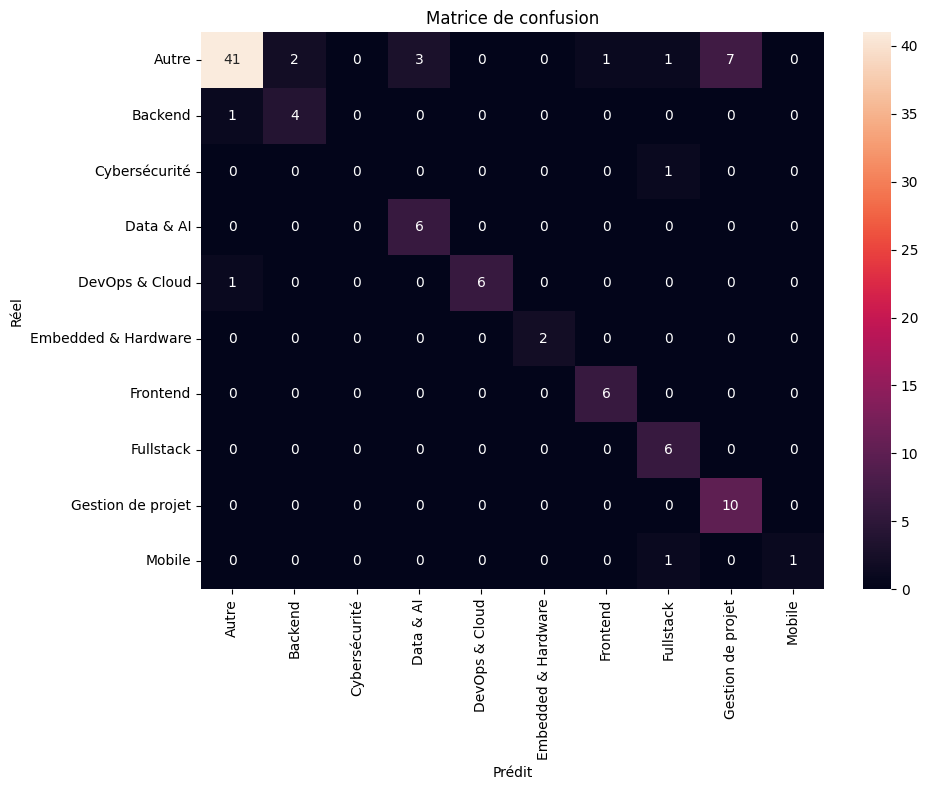

In [15]:
labels = sorted(set(y))
cm = confusion_matrix(y_test, y_pred, labels=labels)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=labels, yticklabels=labels, ax=ax)
ax.set_xlabel("Prédit")
ax.set_ylabel("Réel")
ax.set_title("Matrice de confusion")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

## 5. Export ONNX

In [16]:
initial_type = [("input", StringTensorType([None, 1]))]

onnx_model = convert_sklearn(
    model,
    initial_types=initial_type,
    target_opset=17,
)

output_path = "classifier.onnx"
with open(output_path, "wb") as f:
    f.write(onnx_model.SerializeToString())

size_kb = os.path.getsize(output_path) / 1024
print(f"Modèle exporté : {output_path} ({size_kb:.1f} KB)")

Modèle exporté : classifier.onnx (163.6 KB)


## 6. Vérification de l'inférence ONNX

In [18]:
import onnxruntime as rt

sess = rt.InferenceSession("classifier.onnx")
input_name = sess.get_inputs()[0].name
label_name = sess.get_outputs()[0].name

test_cases = [
    "Développeur React TypeScript frontend",
    "Data Scientist machine learning Python",
    "DevOps Engineer Kubernetes AWS CI/CD",
    "iOS Developer Swift mobile app",
    "Backend Node.js REST API PostgreSQL",
    "Pentester sécurité ethical hacking",
]

for text in test_cases:
    pred = sess.run([label_name], {input_name: np.array([[text]])})[0]
    print(f"  '{text}' → {pred[0]}")

  'Développeur React TypeScript frontend' → Frontend
  'Data Scientist machine learning Python' → Data & AI
  'DevOps Engineer Kubernetes AWS CI/CD' → DevOps & Cloud
  'iOS Developer Swift mobile app' → Mobile
  'Backend Node.js REST API PostgreSQL' → Backend
  'Pentester sécurité ethical hacking' → Cybersécurité


## 7. Sauvegarde des classes

In [19]:
classes = model.classes_.tolist()
with open("classes.json", "w") as f:
    json.dump(classes, f, ensure_ascii=False, indent=2)

print("Classes sauvegardées :", classes)

Classes sauvegardées : ['Autre', 'Backend', 'Cybersécurité', 'Data & AI', 'DevOps & Cloud', 'Embedded & Hardware', 'Frontend', 'Fullstack', 'Gestion de projet', 'Mobile']


## 8. Export JSON (pour Node.js)

In [21]:
tfidf = model.named_steps["tfidf"]
clf   = model.named_steps["clf"]

model_json = {
    "vocabulary":   {k: int(v) for k, v in tfidf.vocabulary_.items()},
    "idf":          tfidf.idf_.tolist(),
    "coef":         clf.coef_.tolist(),
    "intercept":    clf.intercept_.tolist(),
    "classes":      clf.classes_.tolist(),
    "ngram_range":  list(tfidf.ngram_range),
    "sublinear_tf": bool(tfidf.sublinear_tf),
}

with open("classifier.json", "w") as f:
    json.dump(model_json, f, ensure_ascii=False)

size_kb = os.path.getsize("classifier.json") / 1024
print(f"Modèle exporté : classifier.json ({size_kb:.1f} KB)")

Modèle exporté : classifier.json (526.9 KB)
